# Notebook 3 — Measuring Retrieval

Notebooks 1 and 2 showed each method on a few questions, and those questions were picked to
show an effect. That is a good way to explain a method, and a bad way to choose one. This
notebook measures instead: a fixed set of test questions, two simple scores, and the time
per question, for six methods. Then we repeat the test on a public dataset to see whether
the winner stays the same.

**What you will learn**

1. How to build a small test set: questions where you know which chunk holds the answer.
2. How **hit@k** and **MRR** are counted.
3. How six retrieval methods compare on quality and on time.
4. Why an easy test set hides differences, and why the best method depends on the data.
5. How to choose a retriever for your own documents.

**Before you start**

```bash
ollama pull nomic-embed-text
ollama pull gpt-oss:20b
uv sync
```

Then choose the `.venv` Python kernel for this notebook. ⏱️ About 40 minutes, of which about
15 are waiting: two methods send every test question through the chat model.

## 1. Setup

The same knowledge base and the same 21 chunks (LlamaIndex: **nodes**) as in Notebooks 1
and 2: the handbook and the IT FAQ, split at Markdown headings into chunks of up to 500
characters.

In [1]:
import json
import logging
import os
import time
import urllib.request
from pathlib import Path

# Keep the output readable: no download bars, and no note about Hugging Face rate limits.
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)

import matplotlib.pyplot as plt
import numpy as np
from huggingface_hub.utils import logging as hf_logging
from langchain_text_splitters import Language, RecursiveCharacterTextSplitter
from llama_index.core import VectorStoreIndex
from llama_index.core.postprocessor import LLMRerank, SentenceTransformerRerank
from llama_index.core.retrievers import QueryFusionRetriever
from llama_index.core.schema import QueryBundle, TextNode
from llama_index.embeddings.ollama import OllamaEmbedding
from llama_index.llms.ollama import Ollama
from llama_index.retrievers.bm25 import BM25Retriever

from roadmap import get_settings
from roadmap.llm import supports_thinking
from roadmap.loaders import load_html, load_text

hf_logging.set_verbosity_error()

settings = get_settings()
embed_model = OllamaEmbedding(
    model_name=settings.embed_model, base_url=settings.ollama_host, embed_batch_size=32
)
llm = Ollama(
    model=settings.chat_model,
    base_url=settings.ollama_host,
    temperature=0,
    thinking="low" if supports_thinking(settings.chat_model) else None,
    context_window=8192,
    request_timeout=180,
)

DATA = Path("../02-rag-fundamentals/data")
ASSETS = Path("assets")
CACHE = Path(".cache")
CACHE.mkdir(exist_ok=True)

splitter = RecursiveCharacterTextSplitter.from_language(
    Language.MARKDOWN, chunk_size=500, chunk_overlap=50
)
documents = load_text(DATA / "handbook.md") + load_html(DATA / "it_faq.html")
nodes = [
    TextNode(text=chunk.page_content, id_=f"chunk-{i:02d}")
    for i, chunk in enumerate(splitter.split_documents(documents))
]
print(len(nodes), "nodes")

21 nodes


## 2. A test set

To measure retrieval we need questions with a known answer. Here the answer is a chunk: for
each question we note a short phrase that only the right chunk contains. A retrieved chunk
is right when it contains the phrase. Phrases are easier to keep than chunk ids, which change
whenever the chunking changes.

The 32 questions come in three groups:

- **Stage 2** (19): the test questions from Stage 2, Notebook 2, where we compared chunk
  sizes. Most of them use the handbook's own words.
- **Exact terms** (6): numbers, names, and codes such as "4400", "Brightleaf-Print", or
  "31 March".
- **Other words** (7): facts asked in everyday words, such as "unwell" instead of "sick", or
  "phone bill" instead of "phone costs".

In [2]:
TEST_SET = {
    "Stage 2": {
        "Can I eat in company vehicles?": "Eating and drinking in company vehicles",
        "How many vacation days do I get?": "28 vacation days",
        "How much is the learning budget?": "learning budget of 1,200",
        "When do I need a doctor's note?": "doctor's note is required",
        "How much can a hotel cost per night?": "Hotels may cost up to 150 EUR",
        "Can I work from another country?": "Working from another country is allowed",
        "Who pays a parking fine?": "Parking fines",
        "How much of my phone costs are covered?": "Phone costs are covered up to 40 EUR",
        "How long is paid parental leave?": "16 weeks of paid parental leave",
        "Is there money for my home internet?": "home office allowance of 30 EUR",
        "What happens to unused vacation days?": "Up to five unused vacation days",
        "What should I do in case of fire?": "In case of fire",
        "How do I reset my password?": "Forgot password",
        "Do I need the VPN for email?": "It is not needed for email or chat",
        "What is the Wi-Fi password for visitors?": "Brightleaf-Guest",
        "How many color pages can I print?": "Color printing is limited to 50 pages",
        "Are files on my laptop backed up?": "Files saved only on your laptop are not backed up",
        "I clicked a link in a phishing email. What now?": "If you already clicked a link",
        "How often are laptops replaced?": "Laptops are replaced every four years",
    },
    "exact terms": {
        "Who do I call on extension 4400?": "extension 4400",
        "What does 90 days mean for my files?": "restored for 90 days",
        "What is Brightleaf-Print?": "Brightleaf-Print",
        "What is the Brightleaf-Staff network for?": "Brightleaf-Staff",
        "What happens after 31 March to carried-over days?": "used by 31 March",
        "Do gifts over 50 EUR need to be declared?": "worth more than 50 EUR",
    },
    "other words": {
        "I feel unwell, what should I do?": "If you are sick",
        "How many days off do I get each year?": "28 vacation days",
        "How much of the phone bill does Brightleaf pay?": "Phone costs are covered up to 40 EUR",
        "Can I snack in the company car?": "Eating and drinking in company vehicles",
        "Can I fly business class on a work trip?": "Flights must be in economy class",
        "How much time off do I get when my baby is born?": "paid parental leave",
        "My computer is really slow, any tips?": "Restart it first",
    },
}
TESTS = [(question, phrase) for group in TEST_SET.values() for question, phrase in group.items()]

# Each phrase must be in exactly one chunk, or the test measures the wrong thing.
for question, phrase in TESTS:
    found = sum(phrase in node.text for node in nodes)
    assert found == 1, f"{phrase!r} is in {found} chunks ({question})"
print(len(TESTS), "questions, each phrase is in exactly one chunk")

32 questions, each phrase is in exactly one chunk


The check matters. If you change the chunk size later, a phrase can be cut in two, or land in
two chunks because of the overlap, and the test would quietly measure the wrong thing.

## 3. Two scores: hit@k and MRR

![How hit@k and MRR are counted](assets/metrics.svg)

- **hit@k**: the share of questions whose right chunk is somewhere in the top k. **hit@3**
  matters most here, because the top 3 chunks go into the prompt. **hit@1** is stricter:
  is the right chunk first?
- **MRR** (mean reciprocal rank): the average of 1 / rank. First place counts 1, second 0.5,
  third 0.33, a miss 0. One number that rewards a high place.

We also time each method. A method that is a little better but a hundred times slower may
not be worth it.

In [3]:
def rank_of(hits, phrase: str) -> int | None:
    """1-based rank of the first hit that contains the phrase, or None if it is missing."""
    return next((rank for rank, hit in enumerate(hits, 1) if phrase in hit.node.text), None)


def evaluate(retrieve, tests) -> tuple[list, float]:
    """Ask every test question; return the right chunk's rank for each, and ms per question."""
    retrieve(tests[0][0])  # warm-up: the first call loads the models
    start = time.perf_counter()
    ranks = [rank_of(retrieve(question), phrase) for question, phrase in tests]
    return ranks, (time.perf_counter() - start) * 1000 / len(tests)


def hit_at(ranks, k: int) -> float:
    return sum(rank is not None and rank <= k for rank in ranks) / len(ranks)


def mrr(ranks) -> float:
    return sum(1 / rank for rank in ranks if rank) / len(ranks)


def report(results: dict) -> None:
    print(f"{'method':<24}{'hit@1':>7}{'hit@3':>7}{'MRR':>7}{'ms per question':>17}")
    for name, (ranks, ms) in results.items():
        scores = f"{hit_at(ranks, 1):>7.2f}{hit_at(ranks, 3):>7.2f}{mrr(ranks):>7.2f}"
        print(f"{name:<24}{scores}{ms:>17,.1f}")


example = [1, 3, None]  # the diagram: right chunk first, third, and missing
print(f"hit@1 {hit_at(example, 1):.2f}   hit@3 {hit_at(example, 3):.2f}   MRR {mrr(example):.2f}")

hit@1 0.33   hit@3 0.67   MRR 0.44


## 4. Six methods, one test

| Method | What it does | Seen in |
|---|---|---|
| vector | embedding search | Stage 2 |
| BM25 | keyword search | Notebook 2 |
| hybrid | vector + BM25, merged with reciprocal rank fusion | Notebook 2 |
| multi-query | the model writes 3 more versions of the question; vector search for each, merged with reciprocal rank fusion | Notebook 1 |
| hybrid + cross-encoder | hybrid's 10 candidates, reordered by a small cross-encoder | Notebook 2 |
| hybrid + LLM rerank | hybrid's 10 candidates, reordered by `gpt-oss` | Notebook 2 |

Every method returns 10 chunks (`K = 10`), so the rerankers get the same 10 candidates to
reorder. Multi-query uses LlamaIndex's `QueryFusionRetriever` with `num_queries=4` (the
question plus three versions) and the prompt that worked in Notebook 1: use handbook words,
leave out the company name.

This cell takes a few minutes: multi-query calls the chat model once per question, and the
LLM reranker twice (it reads the 10 candidates in two batches of 5).

In [4]:
K = 10
vector_index = VectorStoreIndex(nodes, embed_model=embed_model)
vector = vector_index.as_retriever(similarity_top_k=K)
bm25 = BM25Retriever.from_defaults(nodes=nodes, similarity_top_k=K)


def fusion(retrievers, num_queries: int = 1, **kwargs) -> QueryFusionRetriever:
    return QueryFusionRetriever(
        retrievers,
        llm=llm,  # writes the extra questions; required even when num_queries=1
        mode="reciprocal_rerank",
        num_queries=num_queries,
        similarity_top_k=K,
        use_async=False,
        **kwargs,
    )


MULTI_QUERY_PROMPT = (
    "Write {num_queries} short search queries that would find the answer to this question in "
    "an employee handbook. Use the words a handbook would use, not the words of the question, "
    "and leave out the company name. One query per line, nothing else.\n"
    "Question: {query}\nQueries:\n"
)
hybrid = fusion([vector, bm25])
multi_query = fusion([vector], num_queries=4, query_gen_prompt=MULTI_QUERY_PROMPT)
cross_encoder = SentenceTransformerRerank(model="cross-encoder/ms-marco-MiniLM-L6-v2", top_n=K)
llm_reranker = LLMRerank(llm=llm, top_n=K, choice_batch_size=5)


def rerank(first_stage, reranker):
    """A retrieve function: candidates from the first stage, reordered by the reranker."""

    def retrieve(question: str):
        candidates = first_stage.retrieve(question)
        return reranker.postprocess_nodes(candidates, query_bundle=QueryBundle(question))

    return retrieve


METHODS = {
    "vector": vector.retrieve,
    "BM25": bm25.retrieve,
    "hybrid": hybrid.retrieve,
    "multi-query": multi_query.retrieve,
    "hybrid + cross-encoder": rerank(hybrid, cross_encoder),
    "hybrid + LLM rerank": rerank(hybrid, llm_reranker),
}
results = {name: evaluate(retrieve, TESTS) for name, retrieve in METHODS.items()}
report(results)

method                    hit@1  hit@3    MRR  ms per question
vector                     0.84   0.97   0.90             14.3
BM25                       0.88   0.94   0.91              0.2
hybrid                     0.94   0.97   0.96             15.8
multi-query                0.81   1.00   0.90          1,329.8
hybrid + cross-encoder     0.94   0.97   0.96             30.8
hybrid + LLM rerank        1.00   1.00   1.00          4,776.9


**What to notice**

- Every method finds the right chunk in its top 3 for at least 30 of the 32 questions
  (hit@3 0.94 or more). On a small knowledge base all methods are good; the differences are
  in the order.
- **Hybrid** puts the right chunk first more often than vector search or BM25 alone (0.94
  against 0.84 and 0.88), in about the time of a vector search.
- **Multi-query** is the only first-stage method with every right chunk in its top 3, but it
  puts fewer of them first (0.81), and it costs a chat-model call per question.
- The **cross-encoder** does not change the scores here: it helps one question and hurts
  another (see the groups below).
- The **LLM reranker** scores best: here it puts the right chunk first for every question.
  It is also by far the slowest.

## 5. Quality against time

The two charts show the same numbers. The first compares quality, the second puts quality
next to the time it costs. The time axis is logarithmic: each step is ten times slower.

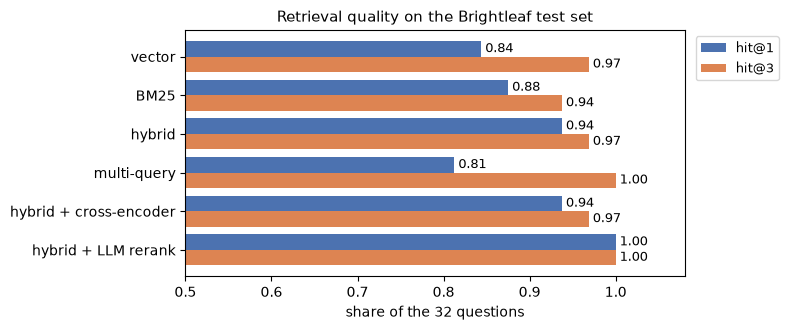

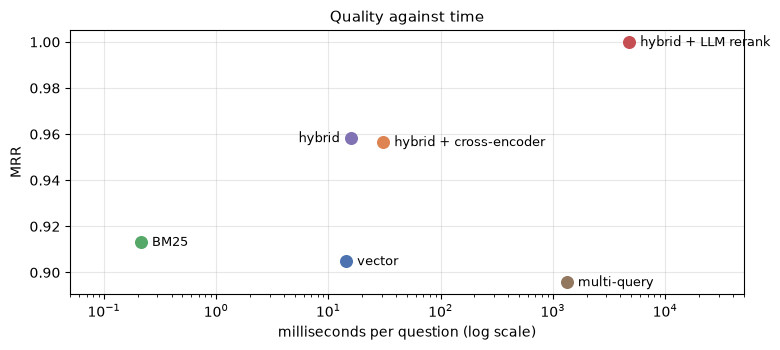

In [5]:
names = list(results)
colors = ["#4C72B0", "#55A868", "#8172B3", "#937860", "#DD8452", "#C44E52"]

fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(names))
hit1 = [hit_at(ranks, 1) for ranks, _ in results.values()]
hit3 = [hit_at(ranks, 3) for ranks, _ in results.values()]
ax.barh(y - 0.2, hit1, height=0.4, color="#4C72B0", label="hit@1")
ax.barh(y + 0.2, hit3, height=0.4, color="#DD8452", label="hit@3")
for row, (one, three) in enumerate(zip(hit1, hit3, strict=True)):
    ax.text(one, row - 0.2, f" {one:.2f}", va="center", fontsize=9)
    ax.text(three, row + 0.2, f" {three:.2f}", va="center", fontsize=9)
ax.set_yticks(y, names)
ax.invert_yaxis()
ax.set_xlim(0.5, 1.08)
ax.set_xlabel("share of the 32 questions")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
ax.set_title("Retrieval quality on the Brightleaf test set", fontsize=11)
fig.tight_layout()
fig.savefig(ASSETS / "retrieval_quality.png", dpi=120)
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.6))
for (name, (ranks, ms)), color in zip(results.items(), colors, strict=True):
    ax.scatter(ms, mrr(ranks), s=70, color=color, zorder=3)
    left = name == "hybrid"  # its neighbor, hybrid + cross-encoder, is labeled on the right
    ax.annotate(
        name,
        (ms, mrr(ranks)),
        textcoords="offset points",
        xytext=(-8, -3) if left else (8, -3),
        ha="right" if left else "left",
        fontsize=9,
    )
ax.set_xscale("log")
ax.set_xlim(0.05, 50_000)
ax.set_xlabel("milliseconds per question (log scale)")
ax.set_ylabel("MRR")
ax.grid(alpha=0.3)
ax.set_title("Quality against time", fontsize=11)
fig.tight_layout()
fig.savefig(ASSETS / "quality_vs_time.png", dpi=120)
plt.show()

The times are from this computer. BM25 needs no model and takes a fraction of a millisecond.
Vector and hybrid search take 10 to 20 ms; most of it is the call that embeds the question.
The cross-encoder adds 15 to 20 ms. Multi-query (over a second) and the LLM reranker (about
5 s) wait for the chat model, more than a hundred times longer. The best place in the
second chart is the top left, high quality for little time, and hybrid search sits there.

## 6. Look at the groups and the misses

An average hides where a method wins and where it loses. Here is how many questions of each
group every method puts **first**:

In [6]:
sizes = {group: len(questions) for group, questions in TEST_SET.items()}
print(f"{'method':<24}" + "".join(f"{group:>14}" for group in TEST_SET))
for name, (ranks, _) in results.items():
    cells, start = "", 0
    for size in sizes.values():
        firsts = sum(rank == 1 for rank in ranks[start : start + size])
        cells += f"{f'{firsts}/{size}':>14}"
        start += size
    print(f"{name:<24}{cells}")

method                         Stage 2   exact terms   other words
vector                           19/19           2/6           6/7
BM25                             19/19           6/6           3/7
hybrid                           19/19           6/6           5/7
multi-query                      17/19           3/6           6/7
hybrid + cross-encoder           19/19           5/6           6/7
hybrid + LLM rerank              19/19           6/6           7/7


- On the 19 **Stage 2** questions, every method except multi-query puts all 19 first. Had we
  tested only these, five of the six methods would look the same. An easy test set hides
  the differences.
- **Exact terms**: BM25 gets 6 of 6, vector search only 2. Hybrid keeps BM25's strength.
- **Other words**: the opposite. Vector search gets 6 of 7, BM25 only 3. Hybrid lands in
  between; the cross-encoder lifts it to 6 and the LLM reranker to 7.
- Multi-query loses two first places on the easy questions: its three rewrites can outvote
  the original question, which already had the right words.

And the misses: questions whose right chunk is not in the top 3. These are the cases to read
one by one, because they tell you what to fix.

In [7]:
for name, (ranks, _) in results.items():
    misses = [
        (question, rank)
        for (question, _), rank in zip(TESTS, ranks, strict=True)
        if not rank or rank > 3
    ]
    print(f"{name}:")
    for question, rank in misses:
        print(f"   {question:<50} right chunk {f'#{rank}' if rank else 'not in the top 10'}")
    if not misses:
        print("   none")

vector:
   How much of the phone bill does Brightleaf pay?    right chunk #8
BM25:
   I feel unwell, what should I do?                   right chunk #7
   How much of the phone bill does Brightleaf pay?    right chunk #4
hybrid:
   How much of the phone bill does Brightleaf pay?    right chunk #6
multi-query:
   none
hybrid + cross-encoder:
   How much of the phone bill does Brightleaf pay?    right chunk #9
hybrid + LLM rerank:
   none


One question is hard for almost every method: "How much of the phone bill does Brightleaf
pay?" (Notebook 2 met it too). The handbook says "Phone costs are covered up to 40 EUR",
and the question's words "Brightleaf" and "pay" match other chunks better. The
cross-encoder even moves it down, from #6 to #9. Only multi-query, with its rewritten
questions, and the LLM reranker get it into the top 3.

## 7. A second test: SQuAD

The Brightleaf test is small: 21 chunks, and 32 questions that we wrote ourselves. Would the
ranking of the methods hold on other data? Let's repeat the test on **SQuAD v1.1**, the open
question dataset from Stage 3 (license: CC BY-SA 4.0). In Stage 3 we searched its questions;
here we search its **paragraphs**. People read a Wikipedia paragraph and wrote questions
about it, so every question has a known right chunk: its paragraph. The whole paragraph text
works as the phrase for `rank_of`.

We take the development set (2,067 paragraphs) and 300 of its questions, picked at random
with a fixed seed. Embedding the paragraphs takes about half a minute.

In [8]:
SQUAD_URL = "https://rajpurkar.github.io/SQuAD-explorer/dataset/dev-v1.1.json"
path = CACHE / "dev-v1.1.json"
if not path.exists():
    urllib.request.urlretrieve(SQUAD_URL, path)  # about 5 MB, downloaded once
articles = json.loads(path.read_text(encoding="utf-8"))["data"]

paragraphs = [paragraph for article in articles for paragraph in article["paragraphs"]]
squad_nodes = [TextNode(text=p["context"], id_=f"paragraph-{i}") for i, p in enumerate(paragraphs)]
squad_questions = [(qa["question"], p["context"]) for p in paragraphs for qa in p["qas"]]

rng = np.random.default_rng(0)  # a fixed seed, so every run picks the same questions
squad_tests = [
    squad_questions[i] for i in sorted(rng.choice(len(squad_questions), 300, replace=False))
]

start = time.perf_counter()
squad_index = VectorStoreIndex(squad_nodes, embed_model=embed_model)
print(f"{len(squad_nodes):,} paragraphs embedded in {time.perf_counter() - start:.0f} s")
print(f"{len(squad_questions):,} questions, {len(squad_tests)} picked for the test\n")
print("Example:", squad_tests[0][0])
print("Right paragraph:", squad_tests[0][1][:160], "...")

2,067 paragraphs embedded in 26 s
10,570 questions, 300 picked for the test

Example: The name of the NFL championship game is?
Right paragraph: Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conferenc ...


The four fast methods run on all 300 questions. The LLM steps would take almost an hour
there, so we leave out multi-query, and run the LLM reranker afterwards on every fifth
question (60).

In [9]:
squad_vector = squad_index.as_retriever(similarity_top_k=K)
squad_bm25 = BM25Retriever.from_defaults(nodes=squad_nodes, similarity_top_k=K)
squad_hybrid = fusion([squad_vector, squad_bm25])

squad_methods = {
    "vector": squad_vector.retrieve,
    "BM25": squad_bm25.retrieve,
    "hybrid": squad_hybrid.retrieve,
    "hybrid + cross-encoder": rerank(squad_hybrid, cross_encoder),
}
squad_results = {name: evaluate(retrieve, squad_tests) for name, retrieve in squad_methods.items()}
report(squad_results)

method                    hit@1  hit@3    MRR  ms per question
vector                     0.69   0.83   0.77             52.2
BM25                       0.77   0.90   0.84              0.2
hybrid                     0.79   0.90   0.85             53.2
hybrid + cross-encoder     0.88   0.95   0.91             98.5


The picture changes:

- **BM25 beats vector search** by a wide margin (hit@1 0.77 against 0.69). The people who
  wrote the SQuAD questions had the paragraph in front of them and often reused its words,
  so word matching works well.
- **Hybrid** is again a little better than either one alone.
- The **cross-encoder** now helps a lot: hit@1 goes from 0.79 to 0.88. It was trained on
  MS MARCO, a large set of web search questions, each with a short passage, much like a
  SQuAD question and its paragraph. On Brightleaf it changed nothing.
- Searches take longer than on Brightleaf: there are 2,067 paragraphs to compare instead of
  21 chunks, and the cross-encoder reads longer texts.

Now the LLM reranker, on 60 of the questions. This takes about 10 minutes.

In [10]:
subset = squad_tests[::5]
subset_methods = {
    "hybrid": squad_hybrid.retrieve,
    "hybrid + cross-encoder": rerank(squad_hybrid, cross_encoder),
    "hybrid + LLM rerank": rerank(squad_hybrid, llm_reranker),
}
report({name: evaluate(retrieve, subset) for name, retrieve in subset_methods.items()})

method                    hit@1  hit@3    MRR  ms per question
hybrid                     0.88   0.97   0.92             52.9
hybrid + cross-encoder     0.90   0.97   0.93            103.2
hybrid + LLM rerank        0.88   0.93   0.91          8,568.4


These 60 questions happen to be easier than the 300 (hybrid hit@1 0.88 against 0.79), so
compare within this table only. With 60 questions, one question is worth 0.017, and small
differences are noise. Still, the direction is clear: **the LLM reranker brings no gain on
SQuAD**. Its hit@3 even drops, and it takes several seconds per question, because the
paragraphs are long. It keeps only the candidates it finds relevant (Notebook 2), so a wrong
judgment can push the right paragraph out. On Brightleaf it was the best method.

## 8. What the two tests say

1. **An easy test set hides the differences.** On the 19 Stage 2 questions, five of six
   methods were perfect. Add the questions your users really ask: exact terms and other
   words.
2. **The winner depends on the data.** The cross-encoder lifted hit@1 on SQuAD from 0.79
   to 0.88, and changed nothing on Brightleaf. The LLM reranker was the best on Brightleaf and brought no
   gain on SQuAD.
3. **Hybrid search is a safe base.** It was the best first-stage method on both tests, for
   about the time of a vector search.
4. **Time counts as much as quality.** The LLM steps cost seconds per question: fine for a
   nightly report, slow for a chat.

## 9. Choosing a retriever

| Situation | Start with |
|---|---|
| A new project | Hybrid search (vector + BM25), top 10 |
| Many exact terms: codes, names, numbers | BM25 is strong and almost free; hybrid keeps it |
| Questions in other words than the documents | Hybrid, then try a reranker and measure |
| Answers must be right, time does not matter (reports, batch jobs) | An LLM reranker, if your test shows it helps |
| Every millisecond counts | BM25 or vector search alone |

To test your own retriever:

1. Collect 30 or more questions like your users' questions, each with a phrase that only the
   right chunk contains.
2. Mix the groups: easy questions, exact terms, and other words.
3. Measure hit@3, MRR, and time before and after every change: chunk size, embedding model,
   retriever, reranker.
4. Read the misses one by one. The averages do not tell you why.

## 10. Summary

| Idea | What it means |
|---|---|
| Test set | Questions with a known right chunk, found by a phrase that only that chunk contains |
| hit@k | Share of questions whose right chunk is in the top k |
| MRR | Average of 1 / rank, 0 for a miss; rewards a high place |
| Groups | Easy questions, exact terms, other words: an average over easy questions hides the differences |
| Time per question | The other half of the choice: from under a millisecond to seconds |

**Remember:** measure before you change the retriever, and measure on questions like your
users' questions. The best method on someone else's data may not be the best on yours.

This is the last notebook of Stage 4.

➡️ **Next:** the Stage 4 project, a YouTube Q&A app (coming soon). See the
[Stage 4 README](README.md).